# Install the engine and open a committed artifact

**Question:** Contraste validated the credit-card models of case C01 with the tests of the `riskvalidation` engine. How many of the engine's registered tests did that validation use, what did their lights say, and does the policy installed on your machine colour the committed rows the way the artifact does?

- **Level:** 1, Fundamentals
- **Prerequisites:** none, this is the entry notebook
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- install `riskvalidation` and compare the version you run with the version that baked the committed documents;
- tell the three kinds of document Contraste commits apart (the index, a case manifest and an artifact) and open one of each;
- measure how much of the engine's catalogue a real case exercised;
- colour the committed rows again with the installed policy, and say why a light is a function of the policy and not of the model alone.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt`. Install it once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The next cell prints the version of every package, so that you can compare it with the pins.

In [1]:
# Print the version of every package this notebook uses, to compare it with notebooks/requirements.txt
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import riskvalidation as rv
from riskvalidation import Light, catalogue
from riskvalidation.core.policy import default_policy, packaged_labels, packaged_policy
from riskvalidation.core.result import TestResult

for name in ("riskvalidation", "pandas", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
pandas 3.0.6
matplotlib 3.11.2


## Data

Contraste is a validator's workbench: it fits models on public data, runs the engine's tests on them and commits the result as JSON documents. This notebook reads those documents and runs the engine on what they hold; it fits no model.

- **Owner:** this repository, https://github.com/fsantibanezleal/CAOS_Contraste. The offline pipeline (`data-pipeline/`) and the engine write the documents; the notebook reads them as committed.
- **The three kinds of document** (contract 2): the **index** `data/derived/manifests/index.json` lists the cases; a **manifest** `data/derived/manifests/<case>.json` describes one case and lists its artifacts; an **artifact** `data/derived/<case>/<variant>.json` holds the models, the test rows, the impact and the findings of one variant.
- **The case we open, C01:** retail credit-card PD. Its real data is the UCI Taiwan credit-card file (Yeh, 2009; 30,000 cards; licence class `mirror-allowed`, CC BY 4.0, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).
- **Files read:** `data/derived/manifests/index.json`, `data/derived/manifests/C01.json`, `data/derived/C01/holdout.json` and, for the provenance step, the other nine documents the manifest lists. Paths are relative to the repository root; no raw data is needed.

The next cell finds the repository root (the notebook sits three folders below it), defines a reader and loads the three documents.

In [2]:
# Point at the committed documents (the notebook sits three folders below the repository root) and read three of them
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


index = read_json("manifests/index.json")
manifest = read_json("manifests/C01.json")
holdout = read_json("C01/holdout.json")

## Method

The method of this notebook is the engine's own vocabulary: a registry of tests, a policy that turns a test's p-value into a light, and a `TestResult` row that records the test, the policy and the light together. We first look at the documents that hold the rows, then count what the engine offers against what the case used, then ask the policy to colour the rows again.

### Step 1: the index and the question of the case

The index is the table of contents of everything Contraste commits: how many cases there are, which one the site opens first, and each case's category. The next cell counts the cases by category and prints the question that the manifest of C01 asks.

In [3]:
# Count the cases of the index by category and show the manifest's own question
by_category = Counter(case["category"]["en"] for case in index["cases"])
table = pd.Series(by_category, name="cases").sort_values(ascending=False).to_frame()
print(index["n_cases"], "cases | default case:", index["default_case"])
print(manifest["question"]["en"])
table

22 cases | default case: C01
Does a monotone WoE scorecard match the challengers the literature says can beat it, once calibration is required, and what do the validation tests say when the population shifts?


,cases
Credit scoring,3
Market and counterparty risk,3
Balance sheet: IRRBB and liquidity,3
Provisions,2
Ratings and calibration,2
LGD and EAD,2
Capital and stress testing,2
ML and AI model risk,2
Portfolio capital,1
Operational risk,1


Reading the index: there are 22 cases in 11 categories, and credit scoring and the two balance-sheet and market groups hold three each, so C01 is one case among many and the others reuse the same engine. The question of C01 is two questions: whether a monotone scorecard matches the challengers once calibration is required, and what the validation tests say when the population shifts. The second one is what the tests of this notebook are about.

### Step 2: the manifest and its artifacts

A manifest lists the artifacts of a case with their role: a `models` document holds the fitted models, a `variant` document holds a scenario (the holdout as observed, a drift, a prior shift, label noise, a small sample, a German twin). The next cell lists the ten artifacts of C01 with their sizes.

In [4]:
# The artifacts the manifest of C01 lists: one row per variant, with its role and its size
listing = pd.DataFrame(manifest["artifacts"])[["role", "variant_id", "bytes"]]
listing = listing.sort_values(["role", "variant_id"]).reset_index(drop=True)
listing

,role,variant_id,bytes
0,models,models-german,48573
1,models,models-taiwan,122735
2,models,models-taiwan-small,99833
3,variant,drift-moderate,266960
4,variant,drift-severe,266255
5,variant,german-twin,250890
6,variant,holdout,293332
7,variant,label-noise,269236
8,variant,prior-shift,269422
9,variant,small-sample,234602


Reading the listing: three `models` documents (the Taiwan models, the German models and a small-sample refit) and seven `variant` documents, each between 235 and 293 kilobytes. Every variant has the same envelope, so what you learn on the holdout opens the other six. The next step asks where the numbers come from: which engine release computed the tests of each document, because a committed number is only as old as the engine that baked it.

### Step 3: provenance, the engine that baked the documents

Every artifact records its `provenance`: the truth status of its data (`real-outcomes` for the Taiwan file), the seed and the `riskvalidation` version. The next cell reads the provenance of all ten documents and counts the engine versions, next to the version installed in this kernel.

In [5]:
# The engine release that baked each of the ten documents of C01, next to the release installed here
documents = [read_json(item["path"]) for item in manifest["artifacts"]]
baked_with = Counter(doc["provenance"]["riskvalidation_version"] for doc in documents)
print("engine versions that baked the documents of C01:", dict(baked_with))
print("installed:", rv.__version__, "| documents", sum(baked_with.values()))
print("truth status of the holdout:", holdout["provenance"]["truth_status"])

engine versions that baked the documents of C01: {'1.0.1': 10}
installed: 1.0.1 | documents 10
truth status of the holdout: real-outcomes


All ten documents were baked with `riskvalidation` 1.0.1, the version this notebook runs, and the holdout's data has real outcomes. That equality is what lets the notebook compare the installed engine with the committed rows later without caveats; when a document carries an older version, a notebook says so before it compares anything. Nothing here rewrites a committed document.

### Step 4: how much of the catalogue did C01 use?

The engine registers every test with its identifier, family, null hypothesis, primary source and the kind of decision it supports; `catalogue()` returns that registry. The test identifiers in a result row (`pd.jeffreys`, `disc.auc`) are the same strings, so the registry can be counted against the rows. The next cell groups both by family and draws them side by side.

registered tests: 134 | families: 18
run on the C01 holdout: 15


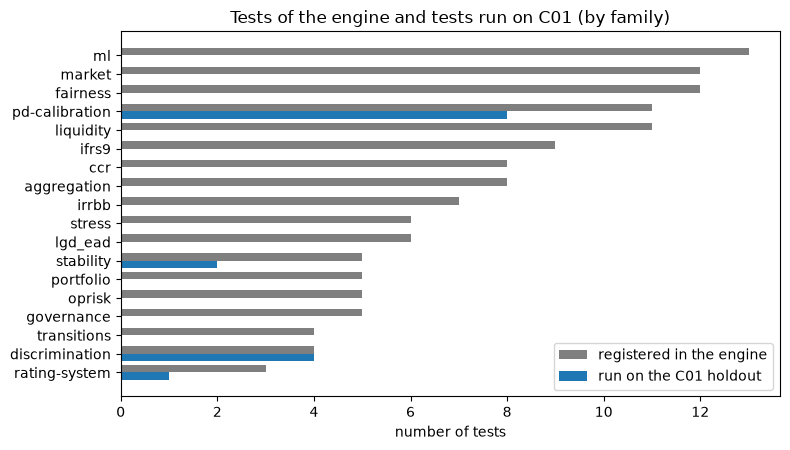

In [6]:
# Count the tests the engine registers by family, and how many of them the C01 holdout artifact ran
family_of = {spec.test_id: spec.family for spec in catalogue()}
registered = Counter(family_of.values())
ran_ids = sorted({row["test_id"] for row in holdout["tests"]})
ran = Counter(family_of[test_id] for test_id in ran_ids)
print("registered tests:", len(family_of), "| families:", len(registered))
print("run on the C01 holdout:", len(ran_ids))

order = sorted(registered, key=registered.get)
positions = range(len(order))
fig, ax = plt.subplots(figsize=(8, 4.6))
up = [p + 0.2 for p in positions]
down = [p - 0.2 for p in positions]
ax.barh(up, [registered[f] for f in order], height=0.4, label="registered in the engine", color="tab:gray")
used = [ran.get(f, 0) for f in order]
ax.barh(down, used, height=0.4, label="run on the C01 holdout", color="tab:blue")
ax.set_yticks(list(positions))
ax.set_yticklabels(order)
ax.set_xlabel("number of tests")
ax.set_title("Tests of the engine and tests run on C01 (by family)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

The grey bars are what the engine offers and the blue bars what the C01 holdout exercised. The case ran 15 of the 134 registered tests, all from four families: every one of the four discrimination tests, eight of the eleven calibration tests, two of the five stability tests and one of the three rating-system tests. The other fourteen families (market risk, liquidity, IFRS 9, counterparty and so on) belong to other cases and to other topics of this notebook set. The figure does not say which tests are the right ones for a credit-card model; it says only how much of the engine this case needed, so that a reader does not take the 134 as the size of one validation.

### Step 5: the policy that turns p-values into lights

A test returns a statistic and a p-value; the colour comes from a policy, a versioned table of thresholds keyed by test identifier. `default_policy()` loads the one the engine packages, and `Policy.threshold(test_id)` returns the threshold of one test, or nothing when the policy holds none. The next cell lists, for the fifteen tests the holdout ran, the kind of threshold, its two cut points and the number of rows that test has in the artifact.

In [7]:
# The packaged policy and, for each test the holdout ran, the threshold it holds (if any) and how many rows the test has
policy = default_policy()
rows_per_test = Counter(row["test_id"] for row in holdout["tests"])
cuts = []
for test_id in ran_ids:
    cut = policy.threshold(test_id)
    kind = "no threshold" if cut is None else cut.kind
    amber = None if cut is None else cut.amber
    red = None if cut is None else cut.red
    cuts.append({"test": test_id, "kind of threshold": kind, "amber": amber, "red": red,
                 "rows": rows_per_test[test_id]})
print("policy:", policy.label)
pd.DataFrame(cuts).sort_values("kind of threshold").reset_index(drop=True)

policy: riskvalidation-default 2026.10.1


,test,kind of threshold,amber,red,rows
0,disc.auc,no threshold,NaN,NaN,8
1,disc.ks,no threshold,NaN,NaN,7
2,pd.brier,no threshold,NaN,NaN,8
3,pd.ece,no threshold,NaN,NaN,8
4,disc.auc_vs_initial,p_value,0.05,0.01,7
5,disc.delong,p_value,0.05,0.01,6
6,pd.binomial,p_value,0.05,0.01,8
7,pd.binomial_vasicek,p_value,0.05,0.01,8
8,pd.chi2_grades,p_value,0.05,0.01,7
9,pd.hosmer_lemeshow,p_value,0.05,0.01,7


Eleven tests carry the same kind of threshold: a p-value turns amber below 0.05 and red below 0.01. Four tests carry none: the AUC, the Kolmogorov-Smirnov statistic, the Brier score and the expected calibration error measure separation and fit, and the default policy sets no cut point for them. Their rows add up to 31, exactly the number of `not_evaluated` rows we meet below, so a missing colour is the policy's decision and never a failure of the test.

### Step 6: the policies the engine packages

The default policy is one of several. A case of Contraste may bring a battery of its own, and the engine packages them all, each with a label and a version. The next cell loads every packaged policy and counts its thresholds.

In [8]:
# The policies the engine packages: every label with the number of tests it holds a threshold for
sizes = {label: len(packaged_policy(label).thresholds) for label in packaged_labels()}
packaged = pd.Series(sizes, name="tests with a threshold").sort_values(ascending=False).to_frame()
print("policies packaged in the engine:", len(sizes))
packaged

policies packaged in the engine: 12


,tests with a threshold
riskvalidation-default 2026.10.1,48
contraste-market-battery 1.0.0,12
contraste-liquidity-battery 1.0.0,11
contraste-ifrs9-battery 1.0.0,9
contraste-aggregation-battery 1.0.0,8
contraste-ccr-battery 1.0.0,8
contraste-c12 1.0.0,7
contraste-irrbb-battery 1.0.0,7
contraste-lgd-ead-battery 1.0.0,6
contraste-stress-battery 1.0.0,6


The engine packages 12 policies. The default one holds 48 thresholds, the broadest by far, and the eleven batteries hold between 5 and 12 each and serve the other cases. The label is the identity of a policy: a result row records it in `policy_version`, so the reader of a committed row always knows which table of thresholds coloured it.

### Step 7: the rows as the engine's own type

The `tests` of an artifact are `TestResult` records written as dictionaries. Rebuilding them as `TestResult` objects is the strictest way to open the artifact: the constructor refuses a row that lacks its null hypothesis, its source or its policy label, or that carries a p-value outside the unit interval. The next cell rebuilds the 187 rows and counts what they hold.

In [9]:
# Rebuild every committed row as the engine's own TestResult, which refuses a row without its null hypothesis or source
results = [TestResult(**{**row, "light": Light(row["light"])}) for row in holdout["tests"]]
with_p_value = sum(result.p_value is not None for result in results)
metric_only = sum(result.p_value is None and result.metric is not None for result in results)
print("rows rebuilt as TestResult:", len(results))
print("with a p-value:", with_p_value, "| with a metric and no p-value:", metric_only)

rows rebuilt as TestResult: 187
with a p-value: 163 | with a metric and no p-value: 24


All 187 rows rebuild without an error: 163 carry a p-value and 24 only a metric. The artifact therefore holds no malformed row, and every row names its null hypothesis and its source. The 24 metric-only rows are the AUC, Brier and calibration-error rows, and the seven other uncoloured rows are the Kolmogorov-Smirnov rows, which have a p-value that the policy does not read.

### Step 8: colour every committed row again

`Policy.classify_row(test_id, row)` takes a result, reads the p-value or metric it needs and returns the light under the policy's threshold. The next cell applies it to all 187 results and crosses the new light with the light the artifact stored.

In [10]:
# Colour every committed row again with the installed policy and cross the new light with the baked one
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
baked = [LIGHT[result.light.value] for result in results]
relit = [LIGHT[policy.classify_row(result.test_id, result)[0].value] for result in results]
rows_axis = pd.Series(baked, name="light baked in the artifact")
crossing = pd.crosstab(rows_axis, pd.Series(relit, name="light of the installed policy"))
print("rows coloured again:", len(relit))
crossing

rows coloured again: 187


light of the installed policy,amber,green,not evaluated,red
light baked in the artifact,,,,
amber,8,0,0,0
green,0,136,0,0
not evaluated,0,0,31,0
red,0,0,0,12


The crossing is diagonal: 136 green rows stay green, 8 amber stay amber, 12 red stay red and 31 stay not evaluated, with nothing off the diagonal. A light is therefore a function of the p-value and the policy, and the engine you installed reproduces the policy that coloured the artifact. The agreement holds because the versions match (the previous step); with another policy or another engine release the same p-values could be coloured differently, which is the subject of notebook 03.

### Step 9: which models drew the lights?

The artifact carries the rows of eight models of the ladder (a constant PD, a one-variable model, the scorecard, two penalised logistic models, a glass-box booster and two gradient boosters). The next cell keeps the portfolio-level rows, counts the lights per model and stacks them.

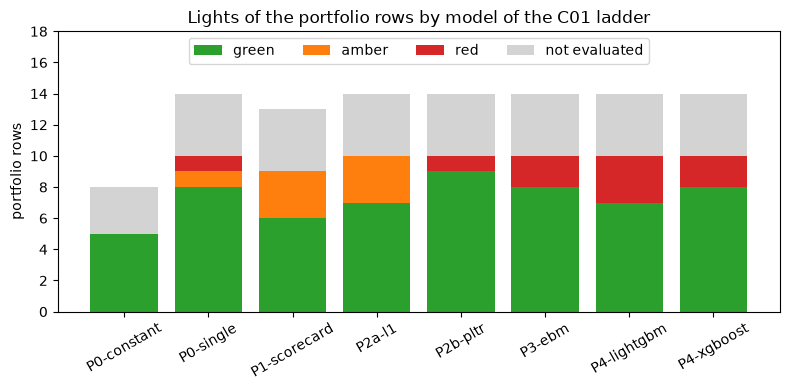

{'green': 58, 'amber': 7, 'red': 9, 'not evaluated': 31}


In [11]:
# The lights of the portfolio rows of each model of the ladder, from the committed artifact
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red", "not_evaluated": "lightgray"}
portfolio = [row for row in holdout["tests"] if row["segment"] == "portfolio" and row["model_id"]]
models = sorted({row["model_id"] for row in portfolio})
counts = Counter((row["model_id"], row["light"]) for row in portfolio)

fig, ax = plt.subplots(figsize=(8, 4))
bottom = [0] * len(models)
for light in colour:
    heights = [counts[(model, light)] for model in models]
    ax.bar(models, heights, bottom=bottom, color=colour[light], label=LIGHT[light])
    bottom = [b + h for b, h in zip(bottom, heights)]
ax.set_ylabel("portfolio rows")
ax.set_title("Lights of the portfolio rows by model of the C01 ladder")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 18)
ax.legend(ncol=4, loc="upper center")
fig.tight_layout()
plt.show()
print({LIGHT[light]: sum(v for (m, l), v in counts.items() if l == light) for light in colour})

Among the portfolio rows there are 58 green, 7 amber, 9 red and 31 not evaluated. Most reds sit on the flexible models: the gradient boosters and the glass-box booster draw two or three red rows each, the scorecard draws none and three amber rows. The constant model, which gives every card the same PD, is green on every test that has a threshold, because its level is right on average; the tests of level cannot see that it ranks nobody, which only the uncoloured AUC would show. The figure counts rows and not severity, and it says nothing about which model is better, only where the tests object.

## Results

**Answer:** Of the 134 tests registered in the engine, the C01 holdout ran 15, drawn from four of the 18 families. Its 187 test rows came out 136 green, 8 amber, 12 red and 31 not evaluated, and the policy installed here (`riskvalidation-default 2026.10.1`, engine 1.0.1) colours all 187 rows exactly as the artifact does.

- **What the number 15 means.** A real validation uses a small, chosen part of the catalogue: the tests that fit the model's decision and its data. The 134 is the size of the toolbox, not of the job.
- **Why 31 rows have no colour.** Four of the fifteen tests have no threshold in the default policy; the uncoloured rows are by design, and a validator reads those numbers against a reference value instead.
- **What the lights do not tell you.** The reds fall on the flexible models and the constant model is green, so a colour measures the agreement of a test with its null hypothesis, not the quality of the model. That is why notebook 02 runs three tests by hand on one model and notebook 03 changes the policy under a fixed p-value.

## Summary

- `riskvalidation` 1.0.1 is installed from the pins of `notebooks/requirements.txt`, and the ten documents of C01 were baked with that same release.
- Contraste commits three kinds of document: the index, one manifest per case and one artifact per variant, all with the same envelope.
- The engine registers 134 tests in 18 families; the credit-card case used 15 of them, and a case always uses a chosen part of the catalogue.
- A light is the result of a policy applied to a p-value: the installed `default_policy()` recolours all 187 committed rows without a single change, and four tests are left uncoloured on purpose.

**What to try next.** Open another artifact of C01, for instance `data/derived/C01/drift-severe.json`, and repeat the stacked figure for it: the reds should move. Then continue with notebook 02, where you call one test yourself on a slice of 50 cards.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- The engine's catalogue and the document contracts: `docs/contracts/engine/` and `docs/contracts/` of this repository.